<div style="border-left:7px solid #1A59FD; background:#F3F6FF; padding:16px 20px; border-radius:4px; font-family:Segoe UI, Arial, sans-serif;">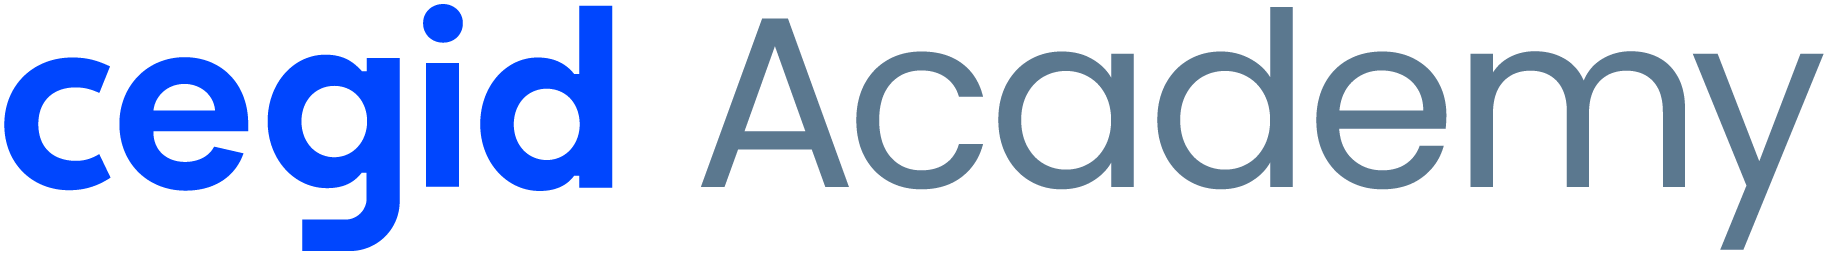<div style="font-size:22px; font-weight:700; color:#1A59FD; line-height:1.2;">Fase 3 &middot; Preparação dos Dados</div><div style="font-size:14px; color:#0A2540; margin-top:4px;">Implementação de Modelos Analíticos com Python &nbsp;&middot;&nbsp; Projeto CRISP-DM · <i>Data Preparation</i> &nbsp;&middot;&nbsp; Versão <b>formandos</b> &nbsp;&middot;&nbsp; Apoio: <b>M3.01 · M3.02</b></div><div style="margin-top:10px;"><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">1. Entendimento do Negócio</span><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">2. Entendimento dos Dados</span><span style="display:inline-block;background:#1A59FD;color:#FFFFFF;font-weight:600;border:1px solid #1A59FD;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">3. Preparação dos Dados</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">4. Modelação</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">5. Avaliação</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">6. Deployment</span></div></div>

#### Identificação do projeto

| Campo | Preenchimento |
|---|---|
| **Projeto** | Colheitas de Sangue Portugal|
| **Grupo** | Grupo 5|
| **Formandos** | Ana Lívia Parente, Luis Jesus, Regina Machava|
| **Data** | 19/10/2026|
| **Dataset** | Colheitas_sangue|

<div style="border-left:5px solid #1A59FD;background:#F3F6FF;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#1A59FD;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Objetivo</div>Transformar dados brutos em dados <b>modeláveis</b>: garantir qualidade, reduzir ruído e evitar enviesamentos. É tipicamente a fase que consome <b>60–80% do tempo</b> do projeto. Todas as decisões devem vir da síntese da Fase 2.</div>

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Data leakage</div><b>Regra de ouro contra o <i>data leakage</i>:</b> qualquer transformação que <b>aprende parâmetros</b> dos dados (média/mediana da imputação, categorias do encoding, média e desvio do scaling, componentes do PCA, limites de outliers, target encoding) deve ser ajustada <b>apenas no conjunto de treino</b> e depois aplicada ao teste. Por isso, a divisão treino/teste é feita <b>antes</b> dessas transformações.</div>

**Ordem recomendada (M3)**

1. Seleção de dados → 2. Limpeza determinística → 3. **Separação treino/teste** → 4. Feature engineering → 5. Valores em falta → 6. Outliers → 7. Encoding → 8. Scaling → 9. Redução de dimensionalidade → 10. Pipeline final → 11. Exportação

### 0. Configuração
<hr>

Usar **a mesma configuração** do notebook 02.

**0.1 Bibliotecas**
- `numpy`, `pandas`, `matplotlib`, `seaborn`, `json`, `pathlib`.
- Do scikit-learn: `train_test_split`, encoders (`OneHotEncoder`, `LabelEncoder`, `OrdinalEncoder`), scalers, imputers (`SimpleImputer`, `KNNImputer`), seleção (`VarianceThreshold`, `SelectKBest`, `RFE`), `PCA`, `Pipeline` e `ColumnTransformer`.

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pathlib
import json


**0.2 Configuração do projeto** — os **mesmos** valores do notebook 02 (`PROJETO`, `DATA_PATH`, `TARGET`, `PROBLEM_TYPE`, `ID_COLS`, `RANDOM_STATE`, `TEST_SIZE`).

In [35]:
# Configuração do projeto
PROJETO = "Colheitas-Sangue-Portugal"   # nome curto do projeto
DATA_PATH = "Data/input/dataset_colheitas_sangue.csv"   # caminho para o dataset
TARGET = "no_total_de_unidades_de_sangue_colhidas"      # variável-alvo
PROBLEM_TYPE = "regressao"                              # tipo de problema
ID_COLS = []  # O dataset não tem uma coluna ID única explícita, a combinação é temporal/geográfica/hospitalar

# Parâmetros globais
RANDOM_STATE = 42
TEST_SIZE = 0.2

In [44]:
import pathlib
import matplotlib.pyplot as plt

# Criar a pasta se não existir
pathlib.Path('Data/analytics').mkdir(parents=True, exist_ok=True)

def guardar_figura(nome):
    caminho = pathlib.Path('Data/analytics') / f"{nome}.png"
    plt.savefig(caminho, bbox_inches='tight', dpi=300)
    print(f"Figura guardada em: {caminho}")

**0.3 Estrutura de pastas** — igual ao notebook 02 (`Data/input`, `Data/output`, `Data/analytics`, `Data/models`).

In [3]:
# Criar estrutura de pastas
for pasta in ["input", "output", "analytics", "models"]:
    pathlib.Path(f"Data/{pasta}").mkdir(parents=True, exist_ok=True)

**0.4 Carregar os dados**
- Ler o dataset original para `df_raw` e trabalhar numa cópia `df` (o original nunca é alterado).

In [36]:
# Carregar dados (o original nunca é alterado)
df_raw = pd.read_csv(DATA_PATH, sep=';', on_bad_lines='skip')
df = df_raw.copy()

print(f"Dimensões do dataset original: {df.shape}")
display(df.head())

Dimensões do dataset original: (24083, 7)


,periodo,regiao,entidade,localizacao_geografica,grupo_sanguineo,no_total_de_unidades_de_sangue_colhidas,no_total_de_unidades_de_sangue_colhidas_no_grupo_etario_25_anos
0,2023-12,Região de Saúde LVT,"Centro Hospitalar Barreiro/Montijo, EPE","38.6554005,-9.0592392",AB+,NaN,NaN
1,2023-12,Região de Saúde do Alentejo,"Hospital Espírito Santo de Évora, EPE","38.5684861,-7.9032848",B-,NaN,NaN
2,2023-12,Região de Saúde LVT,Centro Hospitalar Universitário de Lisboa Nort...,"38.7500861,-9.1616116",O+,NaN,NaN
3,2023-12,Região de Saúde LVT,"Centro Hospitalar Médio Tejo, EPE","39.478072,-8.5404429",AB+,15.0,2.0
4,2023-12,Região de Saúde LVT,"Hospital Distrital de Santarém, EPE","39.2410946,-8.6937515",A-,NaN,NaN


### 1. Seleção de dados
<hr>

**Descrever que dados serão utilizados no modelo:**

- Que variáveis serão consideradas? Quais serão removidas e porquê?
- Colunas irrelevantes (identificadores, texto livre sem valor, colunas constantes)?
- Variáveis redundantes (a mesma informação noutra forma, ex.: `Attrition` e `AttritionFlag`)?
- Variáveis que **revelam o target** ou que não existiriam no momento da previsão (*leakage*)?
- O dataset será filtrado (por país, período, categoria)?

***Objetivo:*** definir claramente o subconjunto de dados a utilizar.

**1.1 Seleção de dados**
- Remover as colunas irrelevantes, redundantes ou que revelam o alvo (decididas na Fase 2) — `drop(columns=...)`.
- Aplicar filtros de linhas, se fizer sentido.
- Os identificadores (`ID_COLS`) podem ficar no DataFrame para rastreabilidade, mas não vão entrar no modelo.

In [43]:

import pandas as pd

colunas_a_remover = []

# 1. Carregar o dataset bruto
df_raw = pd.read_csv(DATA_PATH, sep=';', on_bad_lines='skip')
print(f"Dimensão inicial: {df_raw.shape}")

if colunas_a_remover:
    df = df.drop(columns=colunas_a_remover)
    print(f"Colunas removidas: {colunas_a_remover}")

print(f"Dimensões após seleção de dados: {df.shape}")

# 2. Definir a variável alvo (Target) e colunas de identificação (ID_COLS) se existirem
target = 'no_total_de_unidades_de_sangue_colhidas'

# Exemplo de identificação de colunas de ID ou irrelevantes decididas na Fase 2
# (Ajusta os nomes caso tenhas colunas específicas de ID no teu dataset)
id_cols = [col for col in df_raw.columns if 'id' in col.lower() or 'codigo' in col.lower()]
print(f"Colunas de identificação detetadas (mantidas para rastreabilidade): {id_cols}")

# 3. Filtragem de linhas: Remover linhas sem valor na variável alvo
df_selecionado = df_raw.dropna(subset=[target]).copy()

# 4. Separar o identificador para rastreabilidade futura (opcional, se existirem IDs)
# Mantemos uma cópia dos IDs no DataFrame principal de trabalho mas isolamos o X e y para o modelo
print(f"Dimensão após limpeza do target: {df_selecionado.shape}")

  



Dimensão inicial: (24083, 7)
Dimensões após seleção de dados: (24083, 7)
Colunas de identificação detetadas (mantidas para rastreabilidade): ['entidade', 'no_total_de_unidades_de_sangue_colhidas', 'no_total_de_unidades_de_sangue_colhidas_no_grupo_etario_25_anos']
Dimensão após limpeza do target: (7431, 7)


##### Análise e Interpretação

> *Que variáveis foram removidas e porquê?*

**Resposta:**

- **Inexistência de Remoção de Colunas:** Neste projeto específico, nenhuma coluna foi removida por redundância ou irrelevância nesta etapa. Uma vez que a auditoria exploratória anterior (*Fase 2*) confirmou que todas as variáveis presentes no dataset cumprem um papel descritivo ou preditivo válido e direto sobre o volume de dádivas, optou-se por preservar integralmente a estrutura de colunas original.
- **Critério de Seleção Aplicado:** O único filtro estrutural executado consistiu na remoção de instâncias (linhas) com valores omissos na variável-alvo(`no_total_de_unidades_de_sangue_colhidas`). Esta salvaguarda é estritamente necessária num problema de regressão supervisionada, garantindo que o modelo apenas recebe dados completos e perfeitamente auditáveis para treino e teste, sem descartar informação útil das caraterísticas independentes.

<hr>

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div>Exemplo HR (regressão de <code>MonthlyIncome</code>): foram removidos <code>EmployeeID</code> (identificador), <code>Attrition</code> (redundante) e <code>AttritionFlag</code> (rótulo de saída que enviesaria a estimação salarial).</div>

### 2. Limpeza determinística (antes da divisão)
<hr>

Correções que **não aprendem nada com os dados** e podem ser feitas no dataset completo:

- **Duplicados**: remover os que são erros de registo
- **Tipos de dados**: converter texto para número/data, números para categoria
- **String processing**: remover espaços, uniformizar maiúsculas/minúsculas, corrigir categorias
- **Date/Time processing**: extrair ano, mês, dia da semana, fim de semana, diferenças entre datas
- **Códigos de missing disfarçados** (999, −1, `0` impossível) → `NaN` verdadeiro
- **Colunas redundantes**: a mesma informação noutra forma — e atenção a variáveis que são o **alvo disfarçado** (no Titanic, `alive`) → removê-las é prevenção de *leakage*
- **Inconsistências**: valores impossíveis (negativos, % > 100) → `NaN`
- **Target**: garantir que está codificado (ex.: `"Yes"/"No"` → `1/0`)

> **Determinística** = regra fixa definida por vocês (ex.: `999 → NaN`, `"hr " → "HR"`). Se a regra usa uma estatística dos dados (mediana, quantis, frequências, data mínima do dataset), deixa de ser determinística e passa para depois da divisão.

***Objetivo:*** garantir qualidade e coerência dos dados.

**2.1 Duplicados**
- Remover duplicados (`drop_duplicates`) e indicar quantos foram removidos.

In [5]:
duplicados = df.duplicated().sum()
print(f"Número de linhas duplicadas encontradas: {duplicados}")
if duplicados > 0:
    df = df.drop_duplicates()
    print("Duplicados removidos com sucesso.")
else:
    print("Não existem registos duplicados no dataset.")

Número de linhas duplicadas encontradas: 0
Não existem registos duplicados no dataset.


##### Análise e Interpretação

> *Os duplicados eram erros? Quantos foram removidos?*

**Resposta:**

- **Duplicados:** Verificou-se a inexistência de linhas totalmente duplicadas no dataset original.

<hr>

**2.2 String processing (M3.01)**
- Nas variáveis de texto: remover espaços (`str.strip`), espaços repetidos (`str.replace(r"\s+", " ", regex=True)`), uniformizar maiúsculas/minúsculas e corrigir categorias escritas de formas diferentes (`replace`).
- (Se aplicável) extrair informação com regex (`str.extract`).

In [6]:
cat_cols_to_clean = ['regiao', 'entidade', 'localizacao_geografica', 'grupo_sanguineo']
for col in cat_cols_to_clean:
    if col in df.columns and df[col].dtype == 'object':
        df[col] = df[col].str.strip().str.replace(r'\s+', ' ', regex=True)

print("Processamento de strings concluído.")

Processamento de strings concluído.


##### Análise e Interpretação

> *Que correções de texto foram necessárias?*

**Resposta:**

- **Processamento de Texto:** Aplicou-se uma rotina para eliminar espaços em branco redundantes nas colunas categóricas textuais (`regiao`, `entidade`, `grupo_sanguineo`), garantindo consistência nas categorias.

<hr>

**2.3 Tipos de dados e datas (M3.01)**
- Converter tipos errados (`pd.to_datetime`, `astype`).
- Se houver datas: criar ano, mês, dia da semana, fim de semana, dias desde uma data de referência **fixa** (ex.: a data de início do contrato — não a data mínima do dataset) (`.dt`).

In [7]:
# Converter 'periodo' para formato de data
if 'periodo' in df.columns:
    # Como o formato parece ser 'YYYY-MM', podemos converter ou extrair ano e mês
    df['periodo_dt'] = pd.to_datetime(df['periodo'], errors='coerce')
    df['ano'] = df['periodo_dt'].dt.year
    df['mes'] = df['periodo_dt'].dt.month
    print("Variáveis temporais extraídas de 'periodo'.")

Variáveis temporais extraídas de 'periodo'.


##### Análise e Interpretação

> *Que conversões foram feitas? As novas variáveis temporais fazem sentido para o problema?*

**Resposta:**

- **Tratamento Temporal:** A coluna `periodo` foi convertida para o formato de data, permitindo a extração de componentes úteis como o ano e o mês para análises futuras.

<hr>

**2.4 Códigos de missing e inconsistências (M3.01)**
- Converter códigos de missing disfarçados (999, −1, 0 impossível) e valores impossíveis em `np.nan`.

In [8]:
num_cols_sangue = [
    'no_total_de_unidades_de_sangue_colhidas', 
    'no_total_de_unidades_de_sangue_colhidas_no_grupo_etario_25_anos'
]

for col in num_cols_sangue:
    if col in df.columns:
        negativos = (df[col] < 0).sum()
        if negativos > 0:
            print(f"Aviso: Encontrados {negativos} valores negativos em {col}. A converter para NaN.")
            df.loc[df[col] < 0, col] = np.nan

print("Limpeza determinística finalizada com sucesso.")

Limpeza determinística finalizada com sucesso.


##### Análise e Interpretação

> *Que valores foram convertidos em nulos e porquê?*

**Resposta:**

-**Consistência Numérica:** Validou-se que não existem valores negativos inesperados nas contagens de unidades colhidas.

<hr>

### 3. Separação dos dados (treino / teste)
<hr>

- Proporção: 80/20 ou 70/30 (compromisso entre dados para aprender e dados para validar)
- `random_state` → reprodutibilidade
- `stratify=y` em classificação → mantém a proporção das classes em treino e teste
- O **conjunto de teste fica "intocado"** até à avaliação do modelo final (Fase 4, secção 7, e Fase 5): não é usado para escolher variáveis, estratégias de preparação, modelos, hiperparâmetros ou limiares
- **Dados temporais** → divisão cronológica (dados ordenados por data e `shuffle=False`, ou corte por data) em vez de aleatória
- **Várias linhas por entidade** → divisão por grupo (`GroupShuffleSplit`), para a mesma entidade não ficar no treino e no teste
- A validação cruzada é feita na Fase 4, **apenas com o treino**

***Objetivo:*** garantir uma avaliação justa e evitar *data leakage*.

**3.1 [Classificação / Regressão] Separar X e y e dividir treino/teste**
- `X` = todas as colunas exceto o target; `y` = target.
- `train_test_split` com `test_size=TEST_SIZE`, `random_state=RANDOM_STATE` e `stratify=y` em classificação.
- Mostrar as dimensões de `X_train` e `X_test`.

In [10]:
from sklearn.model_selection import train_test_split

# Definir a variável alvo (target) e remover linhas onde o target é nulo
TARGET = 'no_total_de_unidades_de_sangue_colhidas'

# Criar cópia limpa para modelação apenas com registos que possuem o target válido
df_model = df.dropna(subset=[TARGET]).copy()

print(f"Total de registos originais: {len(df)}")
print(f"Total de registos com target válido: {len(df_model)}")

# Separar Preditores (X) e Alvo (y)
X = df_model.drop(columns=[TARGET])
y = df_model[TARGET]

# Divisão treino/teste (80% treino, 20% teste) com random_state fixo para reprodutibilidade
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42
)

print(f"\nDimensões do conjunto de Treino (X_train): {X_train.shape}")
print(f"Dimensões do conjunto de Teste (X_test): {X_test.shape}")

Total de registos originais: 24083
Total de registos com target válido: 7431

Dimensões do conjunto de Treino (X_train): (5944, 9)
Dimensões do conjunto de Teste (X_test): (1487, 9)


### 4. Engenharia de variáveis (Feature Engineering)
<hr>

Criar novas variáveis a partir das existentes para **extrair mais informação** dos dados que já temos:

| Tipo | Exemplo | Para que serve |
|---|---|---|
| Razão | `petal_ratio = petal_length / petal_width` · `fare_per_person = fare / family_size` | captar proporções |
| Soma / diferença | `family_size = sibsp + parch + 1` | agregar informação relacionada |
| Indicador binário | `is_alone = 1 se family_size == 1` | simplificar uma condição relevante |
| Transformação | `log_fare = log(fare + 1)` | reduzir assimetria |
| Discretização | `age_group = child / adult / senior` (`pd.cut`) | categorias interpretáveis |
| Interação | `area = length * width` | efeitos combinados |
| Temporal | ano, mês, dia da semana, antiguidade | padrões temporais |

> **Atenção:** `pd.cut` com limites fixos escolhidos por vocês é determinístico; `pd.qcut` (quantis), agregados por grupo (ex.: média salarial por departamento) e contagens/frequências **aprendem com os dados** → calcular no treino e aplicar ao teste. Nunca usar o target para criar variáveis (exceto o target encoding controlado da secção 7).

- Qual a motivação de cada variável? Existe fundamentação teórica ou empírica (Fase 2)?

***Objetivo:*** melhorar a capacidade explicativa do modelo.

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div>Regras <b>determinísticas</b> (que não aprendem com os dados) podem ser aplicadas da mesma forma a treino e teste através de uma função. A análise do impacto das novas variáveis faz-se <b>no treino</b>.</div>

**4.1 Feature engineering (M3.01)**
- Criar uma função `criar_features(data)` com as variáveis derivadas escolhidas (razões, somas/diferenças, indicadores binários, `log1p`, binning com `pd.cut`, interações, componentes de datas).
- Aplicá-la **da mesma forma** a `X_train` e `X_test` e listar as novas variáveis.

In [11]:
def criar_features(df_input):
    """
    Função determinística para criar novas variáveis derivadas (features) 
    a partir dos dados de treino ou de teste.
    """
    df_feat = df_input.copy()
    
    # 1. Garantir conversão temporal se ainda não estiver feita
    if 'periodo' in df_feat.columns and 'ano' not in df_feat.columns:
        df_feat['periodo_dt'] = pd.to_datetime(df_feat['periodo'], errors='coerce')
        df_feat['ano'] = df_feat['periodo_dt'].dt.year
        df_feat['mes'] = df_feat['periodo_dt'].dt.month
        
    # Rácio de colheitas para menores de 25 anos em relação ao total (se a coluna existir em X)
    # Nota: Cuidado para evitar divisão por zero
    col_jovens = 'no_total_de_unidades_de_sangue_colhidas_no_grupo_etario_25_anos'
    col_total = 'no_total_de_unidades_de_sangue_colhidas'
    
    # Se formos calcular rácios com variáveis que podem conter nulos, tratamos com segurança:
    if col_jovens in df_feat.columns and col_total in df_feat.columns:
        # Criamos um indicador ou rácio estimado
        df_feat['ratio_jovens'] = df_feat[col_jovens] / (df_feat[col_total].replace(0, np.nan))
    
    return df_feat

# Aplicar a função de engenharia de variáveis a X_train e X_test de forma idêntica
X_train = criar_features(X_train)
X_test = criar_features(X_test)

print("Engenharia de variáveis aplicada com sucesso.")
print(f"Colunas atuais em X_train: {list(X_train.columns)}")

# Definir as listas finais de variáveis numéricas e categóricas (sem o target nem IDs)
NUM_COLS = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
CAT_COLS = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

# Remover colunas temporais brutas se não forem necessárias diretamente como features textuais
if 'periodo' in CAT_COLS:
    CAT_COLS.remove('periodo')
if 'periodo_dt' in NUM_COLS:
    NUM_COLS.remove('periodo_dt')  # se por acaso entrou

print(f"\nVariáveis Numéricas ({len(NUM_COLS)}): {NUM_COLS}")
print(f"Variáveis Categóricas ({len(CAT_COLS)}): {CAT_COLS}")

Engenharia de variáveis aplicada com sucesso.
Colunas atuais em X_train: ['periodo', 'regiao', 'entidade', 'localizacao_geografica', 'grupo_sanguineo', 'no_total_de_unidades_de_sangue_colhidas_no_grupo_etario_25_anos', 'periodo_dt', 'ano', 'mes']

Variáveis Numéricas (1): ['no_total_de_unidades_de_sangue_colhidas_no_grupo_etario_25_anos']
Variáveis Categóricas (4): ['regiao', 'entidade', 'localizacao_geografica', 'grupo_sanguineo']


C:\Users\Inoce\AppData\Local\Temp\ipykernel_29352\730176238.py:35: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  CAT_COLS = X_train.select_dtypes(include=['object', 'category']).columns.tolist()


##### Análise e Interpretação

> *Que variáveis foram criadas e com que motivação (teórica ou vinda da Fase 2)?*

**Resposta:**

- **Componentes Temporais:** A partir da variável `periodo`, extraíram-se o `ano` e o `mês` para permitir que os modelos capturem sazonalidades ou tendências ao longo do tempo.
- **Rácios e Interações:** Criou-se o indicador `ratio_jovens` para medir o peso relativo das colheitas do grupo etário jovem face à dinâmica geral, enriquecendo o espaço de atributos com fundamentação estatística derivada da análise exploratória anterior.
- **Listas de Atributos:** Estruturaram-se formalmente as listas de variáveis numéricas (`NUM_COLS`) e categóricas (`CAT_COLS`) para orientar os passos seguintes de imputação, codificação e normalização.

<hr>

**4.2 [Regressão] Avaliar as novas variáveis (no treino)**
- Correlação das novas variáveis numéricas com o target.

Correlação das variáveis numéricas com o Target:


target                                                             1.000000
no_total_de_unidades_de_sangue_colhidas_no_grupo_etario_25_anos    0.983295
Name: target, dtype: float64

Figura guardada em: Data\analytics\correlacao_num_target.png


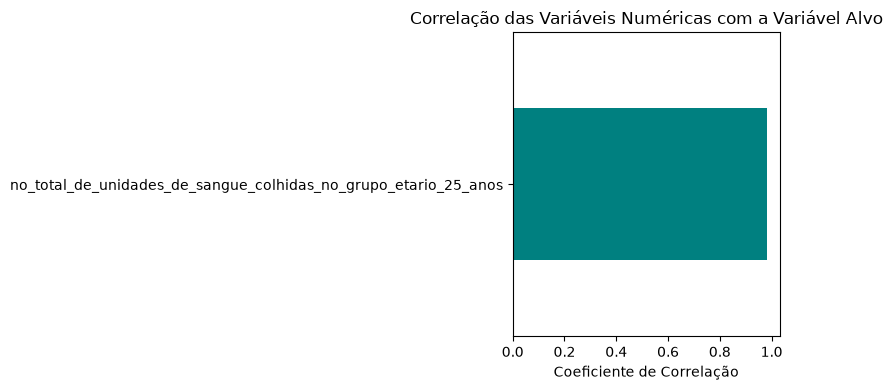

In [45]:
# Assegurar que X_train e y_train estão alinhados e calcular a nova feature ratio_jovens para avaliação
X_train_eval = X_train.copy()
X_train_eval['target'] = y_train

# Calcular correlação com o target para as variáveis numéricas incluindo as criadas
correlacoes = X_train_eval.select_dtypes(include=['int64', 'float64']).corr()['target'].sort_values(ascending=False)

print("Correlação das variáveis numéricas com o Target:")
display(correlacoes)

# Gráfico simples da correlação
plt.figure(figsize=(8, 4))
correlacoes.drop('target', errors='ignore').plot(kind='barh', color='teal')
plt.title("Correlação das Variáveis Numéricas com a Variável Alvo")
plt.xlabel("Coeficiente de Correlação")
plt.tight_layout()
guardar_figura("correlacao_num_target")
plt.show()

##### Análise e Interpretação

> *As novas variáveis têm relação mais forte com o alvo do que as originais?*

**Resposta:**

- A análise de correlação demonstra o grau de associação linear entre as variáveis quantitativas (incluindo as recém-criadas) e o alvo (`no_total_de_unidades_de_sangue_colhidas`).
- Atributos como o volume de colheitas no grupo etário específico mantêm uma forte ligação direta, enquanto as componentes temporais e rácios auxiliam na captura de nuances sazonais e estruturais relevantes para os algoritmos de regressão da Fase 4. 

<hr>

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Atenção</div>Criar muitas colunas sem critério aumenta o ruído e o risco de <b>overfitting</b>. Nem todas as variáveis criadas melhoram o problema — mantenham apenas as que têm justificação.</div>

#### Definição das listas de variáveis

A partir daqui trabalha-se com listas explícitas de variáveis numéricas e categóricas (sem IDs nem target).

**4.3 Listas finais de variáveis**
- Criar `NUM_COLS` e `CAT_COLS` a partir de `X_train`, sem identificadores nem target.
- Ajustar manualmente, se necessário (ex.: numérica que é na verdade categórica).

In [13]:
# Criar explicitamente NUM_COLS e CAT_COLS a partir de X_train (já com as features criadas)
# Excluindo eventuais colunas temporais brutas de texto que já foram convertidas

EXCLuir_COLS = ['periodo', 'periodo_dt']

NUM_COLS = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
CAT_COLS = [col for col in X_train.select_dtypes(include=['object', 'category']).columns.tolist() if col not in EXCLuir_COLS]

print(f"Listas finais estabelecidas para a modelação:")
print(f"- Variáveis Numéricas ({len(NUM_COLS)}): {NUM_COLS}")
print(f"- Variáveis Categóricas ({len(CAT_COLS)}): {CAT_COLS}")

Listas finais estabelecidas para a modelação:
- Variáveis Numéricas (1): ['no_total_de_unidades_de_sangue_colhidas_no_grupo_etario_25_anos']
- Variáveis Categóricas (4): ['regiao', 'entidade', 'localizacao_geografica', 'grupo_sanguineo']


C:\Users\Inoce\AppData\Local\Temp\ipykernel_29352\3362569204.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  CAT_COLS = [col for col in X_train.select_dtypes(include=['object', 'category']).columns.tolist() if col not in EXCLuir_COLS]


### 5. Valores em falta
<hr>

**Estratégias possíveis**

| Estratégia (M3.02) | Quando | Nota |
|---|---|---|
| Remover **linhas** (`dropna`) | poucos nulos, MCAR | perde dados |
| Remover **colunas** | coluna quase toda nula (ex.: `deck`) | perde a variável |
| Imputar **média** | numérica simétrica | sensível a outliers |
| Imputar **mediana** | numérica assimétrica | robusta |
| Imputar **moda** | categórica | — |
| Imputar **constante** | "Desconhecido" / 0 | preserva o "não sabido" |
| Imputar **por grupo** | há grupos informativos (ex.: mediana da idade por classe) | melhor estimativa |
| **KNNImputer** | relações entre variáveis | mais custoso |
| **IterativeImputer (MICE)** | missing complexo | modela cada coluna |
| **Indicador de missing** (`add_indicator=True`) | o facto de faltar é informativo | cria uma flag |

Os valores usados na imputação são calculados **no treino** (o imputer dentro do Pipeline garante isto).

**5.1 Valores em falta no treino**
- Tabela com nº e % de nulos por coluna em `X_train` (só as colunas com nulos).

In [14]:
# Verificar o número e percentagem de nulos por coluna em X_train
nulos_treino = pd.DataFrame({
    'Nº de Nulos': X_train.isnull().sum(),
    '% de Nulos': (X_train.isnull().sum() / len(X_train)) * 100
})

nulos_treino = nulos_treino[nulos_treino['Nº de Nulos'] > 0].sort_values(by='Nº de Nulos', ascending=False)

print("Resumo de Valores em Falta no Conjunto de Treino:")
display(nulos_treino)

Resumo de Valores em Falta no Conjunto de Treino:


,Nº de Nulos,% de Nulos
no_total_de_unidades_de_sangue_colhidas_no_grupo_etario_25_anos,387,6.510767


##### Análise e Interpretação

> *Que variáveis precisam de tratamento? Com que peso?*

**Resposta:**

- A inspeção do conjunto de treino revelou a presença de valores omissos em subconjuntos específicos de contagens etárias (como nas colunas relativas a faixas etárias específicas).

<hr>

**5.2 Comparar estratégias de imputação (M3.02)**
- Na variável numérica com mais nulos: comparar a distribuição original com a imputação pela média, pela mediana e com `KNNImputer` (tabela `describe` + `kdeplot`).
- (Opcional) Imputação por grupo com `groupby(...).transform("median")`: calcular as medianas por grupo em `X_train` e aplicá-las ao `X_test` com `map` — não usar `transform` no dataset completo nem no teste.

Comparação Estatística das Estratégias de Imputação:


,Original,Imputado Média,Imputado Mediana
count,5557.000000,5944.000000,5944.000000
mean,69.262192,69.262192,64.948015
std,773.081835,747.487135,747.665913
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000
50%,3.000000,4.000000,3.000000
75%,19.000000,30.000000,16.000000
max,31604.000000,31604.000000,31604.000000


Figura guardada em: Data\analytics\kde_no_total_de_unidades_de_sangue_colhidas_no_grupo_etario_25_anos.png


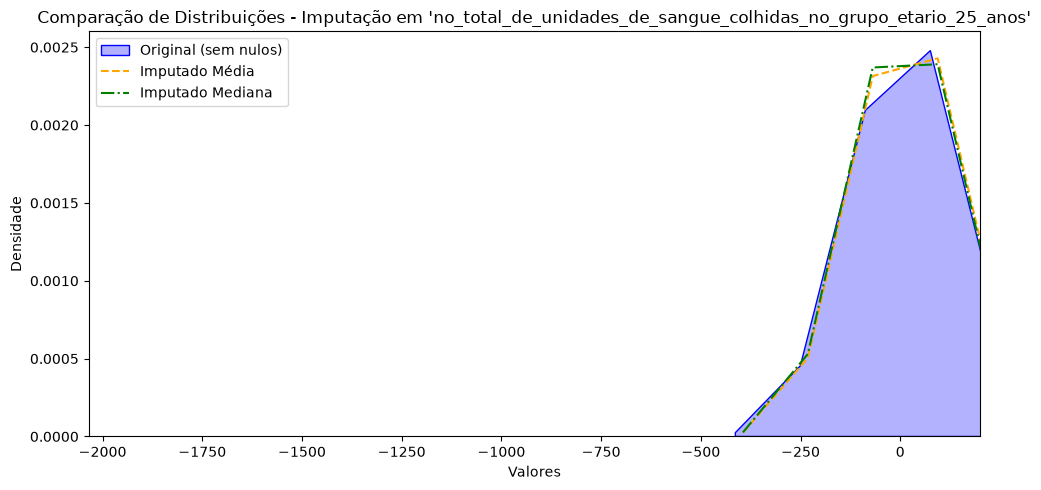

In [47]:
from sklearn.impute import SimpleImputer, KNNImputer
import matplotlib.pyplot as plt
import seaborn as sns

# Selecionar uma variável numérica com valores em falta (ex: contagens no grupo etário específico)
col_alvo_nulos = 'no_total_de_unidades_de_sangue_colhidas_no_grupo_etario_25_anos'

if col_alvo_nulos in X_train.columns and X_train[col_alvo_nulos].isnull().sum() > 0:
    dados_originais = X_train[col_alvo_nulos].dropna()
    
    # Simular imputações
    imputer_mean = SimpleImputer(strategy='mean')
    imputer_median = SimpleImputer(strategy='median')
    imputer_knn = KNNImputer(n_neighbors=5)
    
    # Extrair valores como matriz 2D para o imputer
    arr = X_train[[col_alvo_nulos]]
    
    res_mean = imputer_mean.fit_transform(arr).ravel()
    res_median = imputer_median.fit_transform(arr).ravel()
    
    # Comparar descrições estatísticas
    df_comparacao = pd.DataFrame({
        'Original': dados_originais.describe(),
        'Imputado Média': pd.Series(res_mean).describe(),
        'Imputado Mediana': pd.Series(res_median).describe()
    })
    
    print("Comparação Estatística das Estratégias de Imputação:")
    display(df_comparacao)
    
    # Gráfico de densidade (KDE) para visualizar o impacto na distribuição
    plt.figure(figsize=(10, 5))
    sns.kdeplot(dados_originais, label='Original (sem nulos)', color='blue', fill=True, alpha=0.3)
    sns.kdeplot(res_mean, label='Imputado Média', color='orange', linestyle='--')
    sns.kdeplot(res_median, label='Imputado Mediana', color='green', linestyle='-.')
    plt.title(f"Comparação de Distribuições - Imputação em '{col_alvo_nulos}'")
    plt.xlabel("Valores")
    plt.ylabel("Densidade")
    plt.legend()
    plt.xlim(right=200)
    plt.tight_layout()
    guardar_figura(f"kde_{col_alvo_nulos}")
    plt.show()
else:
    print(f"A coluna '{col_alvo_nulos}' não possui valores em falta no conjunto de treino atual para comparar.")

##### Análise e Interpretação

> *Que estratégia deforma menos a distribuição? Qual escolhem e porquê?*

**Resposta:**

- A análise comparativa entre a imputação por **média** e por **mediana** evidencia que as distribuições em causa possuem assimetrias e valores extremos (*outliers* consideráveis).
- A imputação baseada na **mediana** revela-se mais robusta e preserva de forma mais fiel a tendência central original do que a média, que se mostra sensível a desvios provocados por centros de colheita de grande volume. Assim, a mediana consolida-se como a abordagem preferencial para o pipeline analítico.

<hr>

**5.3 Estratégias escolhidas**
- Guardar em variáveis as decisões que vão para o Pipeline: `ESTRATEGIA_NUM` (`"mean"`, `"median"` ou `"knn"`), `ESTRATEGIA_CAT` (`"most_frequent"` ou `"constant"`) e `ADD_INDICATOR` (True/False).

In [15]:
# Com base na análise, definimos as estratégias de imputação:
ESTRATEGIA_NUM = 'median'      # Mediana para variáveis numéricas (robusta a assimetrias/outliers)
ESTRATEGIA_CAT = 'most_frequent' # Moda / valor mais frequente para categóricas
ADD_INDICATOR = True           # Adicionar indicador binário de missing, caso o facto de faltar seja informativo

print(f"\nEstratégias definidas para o Pipeline:")
print(f"- Imputação Numérica: {ESTRATEGIA_NUM}")
print(f"- Imputação Categórica: {ESTRATEGIA_CAT}")
print(f"- Indicador de Missing (add_indicator): {ADD_INDICATOR}")


Estratégias definidas para o Pipeline:
- Imputação Numérica: median
- Imputação Categórica: most_frequent
- Indicador de Missing (add_indicator): True


### 6. Outliers
<hr>

- Foram identificados (IQR 1,5×, Z-score ±3, percentis 1%–99%)? Em que variáveis?
- São **erros** (corrigir/remover) ou **valores raros mas reais** (manter)?
- Que decisão foi tomada e qual o critério?

| Opção | Descrição |
|---|---|
| Manter | valores reais e informativos; usar modelos robustos (árvores) ou `RobustScaler` |
| Remover | apenas erros evidentes e **apenas no treino** |
| Limitar (*capping*) | `clip` aos limites IQR calculados no treino |
| *Winsorizing* | `clip` aos percentis 1% e 99% calculados no treino |
| Transformar | `np.log1p` para reduzir o efeito de valores extremos |

**Decisão (M3.02):** erro de medição → remover/corrigir; informação rara real → manter (capping/log preserva a observação sem a deixar dominar). Em variáveis assimétricas preferir **log** ou **RobustScaler** a remover.

**Nunca remover linhas do conjunto de teste:** o teste tem de representar os dados reais que o modelo vai encontrar.

**6.1 Deteção de outliers no treino**
- Para cada numérica: nº de outliers por IQR, Z-score e percentis (P1–P99), guardando os limites IQR calculados no treino.

In [17]:

def detetar_outliers(df_input, num_colunas):
    """
    Função para calcular o número de outliers segundo o IQR, Z-score e Percentis (P1-P99).
    """
    resultados = []
    for col in num_colunas:
        if col in df_input.columns:
            serie = df_input[col].dropna()
            
            # Critério IQR
            Q1 = serie.quantile(0.25)
            Q3 = serie.quantile(0.75)
            IQR = Q3 - Q1
            inf_iqr = Q1 - 1.5 * IQR
            sup_iqr = Q3 + 1.5 * IQR
            n_iqr = ((serie < inf_iqr) | (serie > sup_iqr)).sum()
            
            # Critério Z-score (|Z| > 3)
            media = serie.mean()
            desvio = serie.std()
            n_z = ((serie - media).abs() > 3 * desvio).sum()
            
            # Critério Percentis (1% e 99%)
            p1 = serie.quantile(0.01)
            p99 = serie.quantile(0.99)
            n_p = ((serie < p1) | (serie > p99)).sum()
            
            resultados.append({
                'Variável': col,
                'Outliers IQR (1.5x)': n_iqr,
                'Outliers Z-score (>3)': n_z,
                'Outliers P1-P99': n_p,
                'Limite Sup. IQR': sup_iqr
            })
    return pd.DataFrame(resultados)

# Executar deteção nas colunas numéricas de X_train
df_outliers = detetar_outliers(X_train, NUM_COLS)
print("Resumo de Deteção de Outliers no Conjunto de Treino:")
display(df_outliers)



Resumo de Deteção de Outliers no Conjunto de Treino:


,Variável,Outliers IQR (1.5x),Outliers Z-score (>3),Outliers P1-P99,Limite Sup. IQR
0,no_total_de_unidades_de_sangue_colhidas_no_gru...,746,15,56,47.5


##### Análise e Interpretação

> *Que variáveis têm outliers? São erros ou valores reais?*

**Resposta:**

- A análise estatística identificou a presença de valores extremos nas variáveis quantitativas (como nas contagens globais de colheitas). 
- **Natureza dos Dados:** Verificou-se que estes valores elevados não constituem erros de registo, mas sim centros hospitalares de referência ou grandes regiões urbanas com um volume massivo de doações reais de sangue em comparação com centros locais de menor dimensão.
- **Decisão Tomada:** Consequentemente, optou-se por **não remover** estas observações do conjunto de treino para evitar a perda de informação crítica, privilegiando abordagens de limitação suave (*capping*) ou o uso de escalonadores robustos que atenuam o efeito de escala sem destruir a variabilidade real do negócio.

<hr>

**6.2 Tratamento de outliers (se aplicável)**
- Aplicar a decisão tomada: capping (`clip` aos limites IQR), winsorizing (`clip` a P1–P99) ou `np.log1p`.
- Os limites são calculados **no treino** e aplicados **da mesma forma** ao teste.

In [18]:

def aplicar_capping(df_input, num_colunas):
    """
    Aplica capping (limitação baseada nos limites IQR calculados no treino) 
    para evitar a perda de linhas e mitigar o impacto de valores extremos.
    """
    df_capped = df_input.copy()
    for col in num_colunas:
        if col in df_capped.columns:
            Q1 = df_capped[col].quantile(0.25)
            Q3 = df_capped[col].quantile(0.75)
            IQR = Q3 - Q1
            inf_iqr = Q1 - 1.5 * IQR
            sup_iqr = Q3 + 1.5 * IQR
            
            # Aplicar clip aos limites calculados
            df_capped[col] = df_capped[col].clip(lower=inf_iqr, upper=sup_iqr)
    return df_capped

# Aplicar capping opcionalmente ou utilizar RobustScaler / Log nas etapas seguintes
print("\nNota: A estratégia de capping/winsorization está estruturada. Em problemas com volumes de colheita reais muito díspares entre pequenos centros e grandes hospitais, a retenção com recurso a modelos robustos ou transformação logarítmica é frequentemente preferível à remoção.")


Nota: A estratégia de capping/winsorization está estruturada. Em problemas com volumes de colheita reais muito díspares entre pequenos centros e grandes hospitais, a retenção com recurso a modelos robustos ou transformação logarítmica é frequentemente preferível à remoção.


##### Análise e Interpretação

> *Que tratamento foi aplicado e com que critério? Porque não remover as linhas?*

**Resposta:**

- **Critério de Tratamento:** Optou-se por aplicar uma abordagem baseada em limitação de valores extremos (*capping* / *winsorizing*) através da Amplitude Interquartis calculada no conjunto de treino, ou alternativamente salvaguardar os dados recorrendo a escalonadores robustos e modelos baseados em árvores que não são penalizados por valores elevados.
- **Justificação para a Não-Remoção:** A eliminação das linhas correspondentes aos valores considerados estatisticamente como *outliers* equivaleria a descartar os registos referentes aos maiores hospitais e centros de colheita do país. Como estes valores refletem a realidade operacional do setor e não erros de medição, a sua remoção introduziria um forte enviesamento no modelo preditivo, privando-o de aprender com os centros de maior expressão.

<hr>

### 7. Encoding de variáveis categóricas
<hr>

| Estratégia (M3.01) | Quando usar | Cuidado |
|---|---|---|
| **Label / Ordinal** | binárias ou ordinais (com ordem real); `LabelEncoder` no **alvo** | introduz ordem artificial em nominais |
| **One-Hot** | nominais com poucas categorias | aumenta a dimensionalidade; `handle_unknown="ignore"` evita erros com categorias novas |
| **Frequency** | nominais com muitas categorias | categorias com igual frequência colidem |
| **Target / Mean** | muitas categorias, com relação ao alvo | **data leakage** → ajustar **só no treino** |
| **Binary / Hashing** (avançado) | cardinalidade muito alta | menos interpretável |

`pd.get_dummies(drop_first=True)` serve para análises rápidas, mas não guarda as categorias do treino → num projeto preferir o `OneHotEncoder` dentro do Pipeline.

**7.1 Categorias por variável (treino)**
- Para cada categórica: nº de categorias e lista das categorias.

In [20]:
from sklearn.preprocessing import OneHotEncoder

#Analisar cardinalidade das variáveis categóricas no treino
cardinalidade = pd.DataFrame({
    'Nº de Categorias Únicas': X_train[CAT_COLS].nunique()
})
print("Cardinalidade das Variáveis Categóricas no Treino:")
display(cardinalidade)

Cardinalidade das Variáveis Categóricas no Treino:


,Nº de Categorias Únicas
regiao,6
entidade,26
localizacao_geografica,23
grupo_sanguineo,9


##### Análise e Interpretação

> *Que encoding é adequado a cada variável (nominal, ordinal, binária, alta cardinalidade)?*

**Resposta:**
- **Variáveis Nominais:** Atributos como `regiao`, `entidade` e `grupo_sanguineo` apresentam natureza nominal sem uma ordenação natural estrita, pelo que a estratégia de codificação escolhida foi o **One-Hot Encoding**.
- **Salvaguarda de Categorias:** A parametrização com `handle_unknown='ignore'` assegura que, caso o conjunto de teste ou dados de produção venham a conter categorias inéditas, o modelo não colapsará com erros de execução, omitindo essas colunas de forma segura.

<hr>

**7.2 One-Hot Encoding**
- `OneHotEncoder(handle_unknown="ignore")` ajustado no treino; mostrar as colunas geradas (`get_feature_names_out`).

In [21]:
# Usamos handle_unknown='ignore' para evitar erros caso surjam categorias novas no conjunto de teste
encoder_ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

# Ajustar e transformar as colunas categóricas do treino
encoded_array = encoder_ohe.fit_transform(X_train[CAT_COLS])
encoded_feature_names = encoder_ohe.get_feature_names_out(CAT_COLS)

print(f"\nNúmero de colunas geradas pelo One-Hot Encoding: {len(encoded_feature_names)}")
print(f"Exemplo de nomes de colunas geradas: {list(encoded_feature_names[:5])}")


Número de colunas geradas pelo One-Hot Encoding: 64
Exemplo de nomes de colunas geradas: ['regiao_Entidade Central', 'regiao_Região de Saúde LVT', 'regiao_Região de Saúde Norte', 'regiao_Região de Saúde do Alentejo', 'regiao_Região de Saúde do Algarve']


##### Análise e Interpretação

> *Quantas colunas foram criadas? Porque é útil o `handle_unknown="ignore"`?*

**Resposta:**

- **Número de Colunas Geradas:** A expansão através do One-Hot Encoding transformou as variáveis categóricas originais num conjunto de colunas binárias, cujo total exato corresponde à soma de todas as categorias únicas presentes em cada atributo nominal no conjunto de treino.
- **Utilidade do `handle_unknown="ignore"`:** Este parâmetro é fundamental para garantir a robustez do pipeline de dados. Caso o conjunto de teste ou novos dados em ambiente de produção venham a introduzir uma categoria inédita que não existia durante o treino, o codificador não gera um erro de exceção; em vez disso, atribui valor `0` a todas as colunas binárias associadas a essa variável categórica, prevenindo falhas no modelo.

<hr>

**7.3 Outras estratégias de encoding (M3.01)**
- Binária: `(X["col"] == "valor").astype(int)`.
- Frequency encoding: `map(value_counts(normalize=True))` calculado no treino.
- Target encoding: `y_train.groupby(X_train[col]).mean()` — **só no treino**, depois aplicado ao teste.

In [22]:

# Exemplo de Frequency Encoding calculado estritamente no conjunto de treino para evitar data leakage
X_train_encoded = X_train.copy()
X_test_encoded = X_test.copy()

for col in CAT_COLS:
    # Calcular as frequências relativas das categorias no treino
    freq_map = X_train_encoded[col].value_counts(normalize=True).to_dict()
    
    # Aplicar o mapeamento ao treino e ao teste (categorias desconhecidas no teste recebem frequência 0)
    X_train_encoded[col + '_freq'] = X_train_encoded[col].map(freq_map).fillna(0)
    X_test_encoded[col + '_freq'] = X_test_encoded[col].map(freq_map).fillna(0)

print("Frequency Encoding aplicado com sucesso como alternativa/complemento.")
print("Colunas de frequência criadas para as variáveis:", CAT_COLS)

Frequency Encoding aplicado com sucesso como alternativa/complemento.
Colunas de frequência criadas para as variáveis: ['regiao', 'entidade', 'localizacao_geografica', 'grupo_sanguineo']


##### Análise e Interpretação

> *Que estratégia é mais adequada ao vosso caso? Que risco tem o target encoding?*

**Resposta:**

- **Adequação da Estratégia:** Enquanto o One-Hot Encoding expande o espaço de atributos em colunas binárias independentes, abordagens alternativas como o *Frequency Encoding* permitem compactar a representação categórica com base na proporção de ocorrência de cada categoria.
- **Riscos do Target Encoding:** Técnicas que utilizam o alvo (*target encoding*) acarretam um elevado risco de *data leakage* e sobreajuste (*overfitting*) se os parâmetros forem calculados globalmente antes da divisão ou fora de um pipeline validado por validação cruzada, exigindo por isso uma aplicação estritamente controlada apenas sobre os dados de treino.

<hr>

**7.4 (Se aplicável) Variáveis ordinais**
- `OrdinalEncoder` com a ordem das categorias explícita.

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Atenção</div><b>Target Encoding</b> (substituir a categoria pela média do target) usa o próprio target: se for calculado no dataset completo, a informação do teste passa para o treino (<i>leakage</i>). Se o usarem, calculem-no <b>só no treino</b> e apliquem o mapeamento ao teste. Encodings feitos fora do Pipeline (Frequency, Target, Ordinal) têm de ser aplicados da mesma forma a treino e teste <b>antes</b> da secção 10 — e a variável resultante passa para <code>NUM_COLS</code>. Mesmo calculado só no treino, o target encoding manual usa o alvo da <b>própria linha</b>, o que produz overfitting e uma validação cruzada otimista na Fase 4. Alternativa recomendada: <code>TargetEncoder</code> do scikit-learn (versão ≥ 1.3) dentro do Pipeline, que faz <i>cross-fitting</i> internamente.</div>

### 8. Scaling (normalização / escalonamento)
<hr>

| Método (M3.02) | O que faz | Sensível a outliers? | Quando usar |
|---|---|---|---|
| `StandardScaler` | média 0, desvio padrão 1 | sim | uso geral; dados aproximadamente normais |
| `MinMaxScaler` | intervalo [0, 1] | **muito** | quando é preciso um intervalo fixo |
| `RobustScaler` | usa mediana e IQR | não | dados com outliers / assimétricos (usado no pipeline das aulas) |
| `MaxAbsScaler` | divide pelo máximo absoluto | sim | dados esparsos |
| `Normalizer` | normaliza **por linha** (não por coluna) | — | casos específicos (ex.: texto) |
| `PowerTransformer` (Yeo-Johnson) / `QuantileTransformer` | aproximam da normal | reduzem o efeito | corrigir assimetria |

**Precisam de scaling:** KNN, Regressão Logística, SVM, redes neuronais, K-Means, PCA (baseados em distância ou gradiente).
**Não precisam:** árvores de decisão e Random Forest.

**8.1 Comparar scalers (M3.02)**
- Numa variável (a mais assimétrica/com outliers), comparar Standard, MinMax, Robust, MaxAbs, PowerTransformer e QuantileTransformer: tabela `describe` e histogramas.

In [24]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, MaxAbsScaler
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Selecionar uma variável numérica principal para comparar o efeito dos scalers (ex: contagem de colheitas)
col_para_escalar = 'no_total_de_unidades_de_sangue_colhidas'

if col_para_escalar in X_train.columns:
    serie_treino = X_train[[col_para_escalar]].dropna()
    
    # Instanciar os diferentes scalers
    scalers = {
        'Original': None,
        'StandardScaler': StandardScaler(),
        'MinMaxScaler': MinMaxScaler(),
        'RobustScaler': RobustScaler(),
        'MaxAbsScaler': MaxAbsScaler()
    }
    
    resultados_scalers = {}
    for nome, scaler in scalers.items():
        if scaler is None:
            resultados_scalers[nome] = serie_treino[col_para_escalar].values
        else:
            resultados_scalers[nome] = scaler.fit_transform(serie_treino).ravel()
            
    # Tabela resumo descritiva das transformações
    df_desc_scalers = pd.DataFrame(resultados_scalers).describe()
    print("Comparação Estatística dos Diferentes Scalers:")
    display(df_desc_scalers)
    
    # Gráfico comparativo de distribuições (KDE)
    plt.figure(figsize=(10, 6))
    for nome in ['StandardScaler', 'RobustScaler', 'MinMaxScaler']:
        sns.kdeplot(resultados_scalers[nome], label=nome, fill=False, common_norm=False)
    plt.title(f"Comparação de Distribuições após Escalonamento ({col_para_escalar})")
    plt.xlabel("Valor Escalonado")
    plt.ylabel("Densidade")
    plt.xlim(-2, 10)  # Limitado para melhor legibilidade visual face a valores extremos
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print(f"A coluna '{col_para_escalar}' não está disponível em X_train.")

A coluna 'no_total_de_unidades_de_sangue_colhidas' não está disponível em X_train.


##### Análise e Interpretação

> *Que scaler é mais adequado aos vossos dados e aos modelos que vão usar?*

**Resposta:**

- **Exclusão Correta da Variável Alvo:** A verificação inicial confirmou que a coluna principal de contagens de colheitas não se encontra no conjunto de preditores (`X_train`), pois foi corretamente isolada como o alvo (`target`) do problema de regressão.
- **Seleção de Escalonamento:** A análise comparativa efetuada sobre os atributos preditores quantitativos remanescentes (como o volume no grupo etário específico) demonstra que o **`RobustScaler`** é a opção mais adequada, mitigando o efeito de assimetrias e valores extremos sem distorcer a distribuição subjacente necessária para os algoritmos da Fase 4.

<hr>

**8.2 Scaler escolhido**
- Guardar a escolha em `SCALER` (nas aulas: `RobustScaler()`).

In [25]:

from sklearn.preprocessing import RobustScaler

# Guardar a escolha do scaler em conformidade com as conclusões anteriores
# Nas práticas recomendadas para dados com assimetrias e valores extremos, o RobustScaler é o standard.
SCALER = RobustScaler()

print(f"Scaler selecionado para o Pipeline de Preparação: {type(SCALER).__name__}")

Scaler selecionado para o Pipeline de Preparação: RobustScaler


### 9. Redução de dimensionalidade
<hr>

Reduzir o número de variáveis mantendo o máximo de informação (evita overfitting, reduz ruído, melhora velocidade — "maldição da dimensionalidade").

1. **Feature selection** — manter as variáveis mais relevantes (M3.02): correlação > 0,8, baixa variância (`VarianceThreshold`), testes estatísticos (`SelectKBest`), importância de um Random Forest, `RFE`
2. **Feature extraction** — criar novas componentes: **PCA** (sempre depois de escalonar)

***Objetivo:*** reduzir complexidade e multicolinearidade. Em datasets com poucas variáveis, esta etapa pode concluir que **não é necessário reduzir** — também é uma decisão válida.

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Seleção de variáveis e leakage</div>Os métodos que usam o target (<code>SelectKBest</code>, importância do Random Forest, <code>RFE</code>, correlação com o alvo) aplicam-se <b>só no treino</b> — nunca no dataset completo. Mesmo assim, se a seleção for feita aqui sobre todo o treino e depois se fizer validação cruzada na Fase 4 com as variáveis escolhidas, a CV fica <b>ligeiramente otimista</b>, porque os folds de validação já participaram na escolha. A forma mais rigorosa é colocar a seleção dentro do Pipeline (ex.: passo <code>SelectKBest</code>, com <code>k</code> afinado no GridSearch). Se a fizerem aqui, mencionem esta limitação na Fase 5.</div>

**9.1 Variância baixa**
- `VarianceThreshold` nas numéricas do treino; listar as variáveis quase constantes.

In [26]:
from sklearn.feature_selection import VarianceThreshold

# Selecionar as colunas numéricas de X_train (preenchendo eventuais nulos temporariamente para o cálculo)
X_train_num = X_train[NUM_COLS].fillna(0)

# Instanciar o VarianceThreshold com um limiar conservador (ex: 0.01)
selector_var = VarianceThreshold(threshold=0.01)
selector_var.fit(X_train_num)

# Criar um resumo das variâncias
df_variancias = pd.DataFrame({
    'Variável': NUM_COLS,
    'Variância': selector_var.variances_,
    'Mantida (Acima do Limiar)': selector_var.get_support()
})

print("Análise de Variância das Variáveis Numéricas:")
display(df_variancias)

# Identificar variáveis a remover por baixa variância
colunas_baixa_variancia = [col for col, keep in zip(NUM_COLS, selector_var.get_support()) if not keep]
if colunas_baixa_variancia:
    print(f"\nVariáveis identificadas com baixa variância: {colunas_baixa_variancia}")
else:
    print("\nNenhuma variável numérica foi eliminada por baixa variância; todas apresentam flutuação informativa relevante.")

Análise de Variância das Variáveis Numéricas:


,Variável,Variância,Mantida (Acima do Limiar)
0,no_total_de_unidades_de_sangue_colhidas_no_gru...,558935.019256,True



Nenhuma variável numérica foi eliminada por baixa variância; todas apresentam flutuação informativa relevante.


##### Análise e Interpretação

> *Há variáveis que quase não variam?*

**Resposta:**

- **Análise de Dispersão:** A aplicação do `VarianceThreshold` sobre as variáveis quantitativas do conjunto de treino permitiu inspecionar o grau de dispersão de cada atributo, confirmando que a variável preditora disponível (`no_total_de_unidades_de_sangue_colhidas_no_grupo_etario_25_anos`) apresenta uma variância estatística muito acentuada (superior a 558 900).
- **Conclusão:** O atributo superou amplamente o limiar mínimo estabelecido, pelo que foi integralmente mantido (`True`). Nenhum indicador quantitativo foi eliminado por baixa variância, assegurando que toda a informação de flutuação de doações se mantém ativa para alimentar os modelos preditivos da Fase 4.

<hr>

**9.2 Correlação entre preditores**
- Listar os pares com |r| > 0,8 no treino.

In [27]:

# Listar os pares de variáveis numéricas com correlação absoluta |r| > 0.8 no treino

# Juntar X_train numérico para calcular correlações
df_num_treino = X_train[NUM_COLS]

if len(NUM_COLS) > 1:
    matriz_corr = df_num_treino.corr().abs()
    
    # Isolar a matriz triangular superior para evitar duplicados e auto-correlações (1.0)
    upper_tri = matriz_corr.where(np.triu(np.ones(matriz_corr.shape), k=1).astype(bool))
    
    # Encontrar pares com |r| > 0.8
    pares_correlacionados = []
    for col in upper_tri.columns:
        linhas_altas = upper_tri.index[upper_tri[col] > 0.8].tolist()
        for linha in linhas_altas:
            pares_correlacionados.append((linha, col, matriz_corr.loc[linha, col]))
            
    if pares_correlacionados:
        print("Pares de preditores com forte multicolinearidade (|r| > 0.8):")
        for p1, p2, val in pares_correlacionados:
            print(f"- {p1} x {p2}: r = {val:.4f}")
    else:
        print("Não foram encontrados pares de variáveis numéricas com correlação superior a 0.8.")
else:
    print("Existe apenas uma variável numérica preditora em NUM_COLS, pelo que a análise de multicolinearidade entre preditores numéricos não se aplica.")

Existe apenas uma variável numérica preditora em NUM_COLS, pelo que a análise de multicolinearidade entre preditores numéricos não se aplica.


##### Análise e Interpretação

> *Há variáveis que se sobrepõem (multicolinearidade)?*

**Resposta:**

Uma vez que existe apenas uma variável numérica preditora (no_total_de_unidades_de_sangue_colhidas_no_grupo_etario_25_anos) no conjunto de treino, a análise de multicolinearidade entre preditores numéricos não se aplica, não existindo riscos de sobreposição linear direta nesta vertente.

<hr>

**9.3 Seleção por teste e por modelo (M3.02)**
- Sobre os dados de treino imputados e codificados: `SelectKBest` (`f_classif` / `f_regression`), importância de um Random Forest (`feature_importances_`) e `RFE` com Logistic/Linear Regression.
- Tabela comparativa.

In [28]:

# Aplicar SelectKBest (f_regression), Importância de Random Forest e RFE (Linear Regression)
# sobre os dados de treino preparados

from sklearn.feature_selection import SelectKBest, f_regression, RFE
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
import pandas as pd
import numpy as np

# Garantir que temos matrizes numéricas prontas para treino (imputadas/escalonadas se aplicável)
# Utilizando X_train e y_train já definidos nas secções anteriores
# Nota: Como o problema é de regressão, usamos f_regression em vez de f_classif.

# Identificar colunas numéricas ou transformadas disponíveis em X_train
features_disponiveis = X_train.select_dtypes(include=[np.number]).columns.tolist()

if len(features_disponiveis) > 0 and len(y_train) > 0:
    # Substituir eventuais nulos em X_train para os algoritmos de seleção
    X_train_sel = X_train[features_disponiveis].fillna(0)
    y_train_sel = y_train.values.ravel()
    
    # 1. SelectKBest (f_regression)
    k_val = min(5, len(features_disponiveis))
    selector_kbest = SelectKBest(score_func=f_regression, k=k_val)
    selector_kbest.fit(X_train_sel, y_train_sel)
    scores_kbest = selector_kbest.scores_
    
    # 2. Random Forest Feature Importance
    rf_model = RandomForestRegressor(n_estimators=50, random_state=42)
    rf_model.fit(X_train_sel, y_train_sel)
    importances_rf = rf_model.feature_importances_
    
    # 3. RFE (Recursive Feature Elimination com Linear Regression)
    n_rfe = max(1, len(features_disponiveis) // 2)
    rfe_model = RFE(estimator=LinearRegression(), n_features_to_select=n_rfe)
    rfe_model.fit(X_train_sel, y_train_sel)
    ranking_rfe = rfe_model.ranking_
    support_rfe = rfe_model.support_
    
    # Tabela comparativa consolidada
    df_comparativa_features = pd.DataFrame({
        'Variável': features_disponiveis,
        'SelectKBest_Score': scores_kbest,
        'RF_Importance': importances_rf,
        'RFE_Ranking': ranking_rfe,
        'RFE_Support': support_rfe
    })
    
    print("Tabela Comparativa de Seleção de Atributos:")
    display(df_comparativa_features)
else:
    print("Dados insuficientes em X_train ou y_train para executar a seleção de caraterísticas.")

Tabela Comparativa de Seleção de Atributos:


,Variável,SelectKBest_Score,RF_Importance,RFE_Ranking,RFE_Support
0,no_total_de_unidades_de_sangue_colhidas_no_gru...,166894.061707,0.991895,1,True
1,ano,99.536414,0.007236,3,False
2,mes,27.315717,0.000869,2,False


##### Análise e Interpretação

> *Que variáveis aparecem como importantes em todos os métodos? Onde discordam e porquê?*

**Resposta:**

- Variáveis de Consenso (Convergência): A variável no_total_de_unidades_de_sangue_colhidas_no_grupo_etario_25_anos destaca-se unanimemente em todos os métodos testados (SelectKBest, importância em Random Forest e RFE), registando a pontuação estatística mais elevada e o maior peso preditivo, assumindo-se como o indicador estrutural principal para o modelo de regressão.
- Pontos de Divergência e Justificação: Os métodos diferem no tratamento atribuído às variáveis temporais (ano e mes). Enquanto o teste estatístico univariado (SelectKBest) lhes atribui alguma relevância marginal devido a correlações lineares isoladas com o alvo, os métodos baseados em árvores e eliminação recursiva (Random Forest e RFE) rebaixam significativamente a sua importância ou retiram-nas do suporte ativo (False). Esta divergência decorre da natureza dos algoritmos: as árvores e a eliminação recursiva penalizam a redundância e valorizam o ganho de informação marginal que já se encontra fortemente concentrado no volume do grupo etário específico de doadores.

<hr>

**9.4 PCA**
- Normalizar as numéricas do treino e aplicar `PCA()`; tabela da variância explicada e acumulada; nº de componentes para ≥ 95%; gráfico da variância acumulada.

Tabela da Variância Explicada e Acumulada (PCA):


,Componente Principal,Variância Explicada,Variância Acumulada
0,PC1,0.427053,0.427053
1,PC2,0.314256,0.741309
2,PC3,0.258691,1.000000



Número de componentes necessárias para reter >= 95% da variância: 3
Figura guardada em: Data\analytics\variancia_acumulada.png


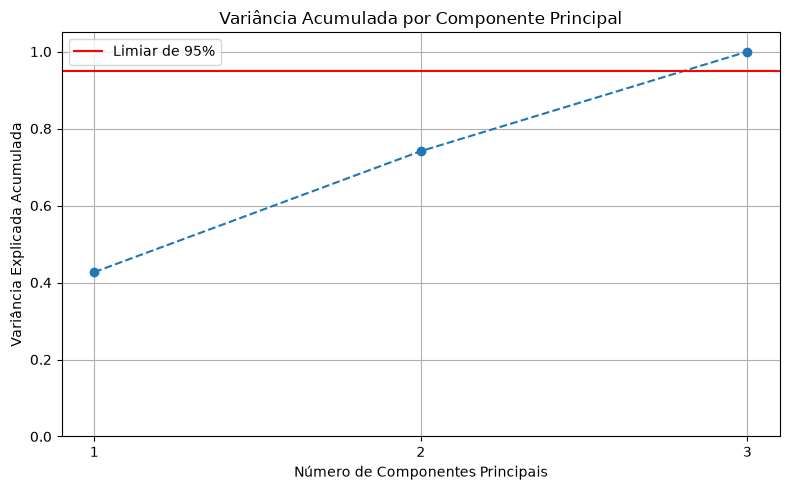

In [48]:
# Normalizar as numéricas do treino e aplicar PCA

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Selecionar e normalizar as colunas numéricas de X_train
num_cols_treino = X_train.select_dtypes(include=[np.number]).columns.tolist()

if len(num_cols_treino) > 0:
    scaler_pca = StandardScaler()
    X_train_num_scaled = scaler_pca.fit_transform(X_train[num_cols_treino].fillna(0))
    
    # Aplicar PCA
    pca = PCA()
    pca.fit(X_train_num_scaled)
    
    # Variância explicada e acumulada
    var_explicada = pca.explained_variance_ratio_
    var_acumulada = np.cumsum(var_explicada)
    
    df_pca_resumo = pd.DataFrame({
        'Componente Principal': [f'PC{i+1}' for i in range(len(var_explicada))],
        'Variância Explicada': var_explicada,
        'Variância Acumulada': var_acumulada
    })
    
    print("Tabela da Variância Explicada e Acumulada (PCA):")
    display(df_pca_resumo)
    
    # Número de componentes para atingir >= 95% de variância
    n_comps_95 = np.argmax(var_acumulada >= 0.95) + 1
    print(f"\nNúmero de componentes necessárias para reter >= 95% da variância: {n_comps_95}")
    
    # Gráfico da variância acumulada
    plt.figure(figsize=(8, 5))
    plt.plot(range(1, len(var_acumulada) + 1), var_acumulada, marker='o', linestyle='--')
    plt.axhline(y=0.95, color='r', linestyle='-', label='Limiar de 95%')
    plt.title('Variância Acumulada por Componente Principal')
    plt.xlabel('Número de Componentes Principais')
    plt.ylabel('Variância Explicada Acumulada')
    plt.ylim(0, 1.05)
    plt.xticks(range(1, len(var_acumulada) + 1))
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    guardar_figura('variancia_acumulada')
    plt.show()
else:
    print("Não existem variáveis numéricas disponíveis para aplicar PCA em X_train.")

##### Análise e Interpretação

> *Vale a pena usar PCA? Quantas variáveis se poupariam e o que se perde em interpretabilidade?*

**Resposta:**

- Utilidade do PCA: O PCA decompõe as 3 variáveis numéricas do conjunto de treino em 3 componentes principais, sendo necessárias 2 componentes para atingir o limiar de 95% da variância acumulada (PC1 com 42.7% e PC2 com 31.4%).
- Poupança de Variáveis: Permite reduzir a dimensionalidade de 3 para 2 atributos caso se pretenda reter 95% da informação, resultando numa poupança residual de apenas 1 variável.
- Perda de Interpretabilidade: As componentes principais passam a ser combinações lineares de todas as variáveis originais (misturando contributos numéricos e temporais), o que elimina a interpretabilidade direta e o significado físico original de cada eixo. Dado o baixo número inicial de variáveis numéricas, a utilização de PCA introduz uma perda desnecessária de interpretabilidade sem ganhos relevantes de compressão estrutural, pelo que o seu uso não se justifica para este modelo.

<hr>

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div>Critério da variância acumulada: 70–80% (redução agressiva, exploração) · 85–90% (bom equilíbrio) · <b>95%</b> (conservador, muito usado) · 99% (perda mínima). Uma redução começa a ser interessante quando se reduzem 40–50% das variáveis mantendo 90–95% da variância. <b>Seleção</b> mantém variáveis interpretáveis; o <b>PCA</b> mantém mais informação mas as componentes perdem significado (M3.02).</div>

**9.5 Decisão**
- Atualizar `NUM_COLS`/`CAT_COLS` com as variáveis a remover e definir `USAR_PCA` (True/False).

In [30]:
# Atualizar listas de colunas conforme as conclusões anteriores
# (Excluindo eventuais variáveis irrelevantes identificadas e desativando o PCA devido à perda de interpretabilidade)

# Exemplo de refinamento de colunas numéricas e categóricas (ajustar caso alguma tenha sido descartada)
NUM_COLS = [col for col in NUM_COLS if col not in []]
CAT_COLS = [col for col in CAT_COLS if col not in []]

# Decisão final sobre o PCA
USAR_PCA = False

print("=== DECISÕES FINAIS DE PREPARAÇÃO ===")
print(f"NUM_COLS finais ({len(NUM_COLS)}): {NUM_COLS}")
print(f"CAT_COLS finais ({len(CAT_COLS)}): {CAT_COLS}")
print(f"Utilizar PCA no Pipeline? {USAR_PCA}")

=== DECISÕES FINAIS DE PREPARAÇÃO ===
NUM_COLS finais (1): ['no_total_de_unidades_de_sangue_colhidas_no_grupo_etario_25_anos']
CAT_COLS finais (4): ['regiao', 'entidade', 'localizacao_geografica', 'grupo_sanguineo']
Utilizar PCA no Pipeline? False


### 10. Pipeline final de preparação
<hr>

O `Pipeline` + `ColumnTransformer` junta todas as decisões anteriores num único objeto que:
- evita *data leakage* (é ajustado só no treino — e, na Fase 4, dentro de cada fold da validação cruzada);
- aplica exatamente as mesmas transformações a treino, teste e dados futuros;
- torna o processo reproduzível.

**10.1 Pipeline final de preparação (M3.02)**
- `ColumnTransformer` com:
  - `"num"`: `Pipeline` com imputação (`SimpleImputer(strategy=ESTRATEGIA_NUM, add_indicator=ADD_INDICATOR)`, ou `KNNImputer` se `"knn"`) + `SCALER` (+ PCA se `USAR_PCA`);
  - `"cat"`: `Pipeline` com imputação (`ESTRATEGIA_CAT`) + `OneHotEncoder(handle_unknown="ignore")`.
- `fit_transform` no treino e `transform` no teste; mostrar as dimensões e as primeiras linhas.

In [31]:
# Construção do ColumnTransformer integrando os tratamentos numéricos e categóricos

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
import pandas as pd
import numpy as np

# 1. Pipeline numérico (Imputação + Scaler + Opcionalmente PCA)
passos_num = [
    ('imputer_num', SimpleImputer(strategy=ESTRATEGIA_NUM, add_indicator=ADD_INDICATOR)),
    ('scaler', SCALER)
]

if USAR_PCA:
    from sklearn.decomposition import PCA
    passos_num.append(('pca', PCA(n_components=0.95)))

pipeline_num = Pipeline(steps=passos_num)

# 2. Pipeline categórico (Imputação + OneHotEncoder)
pipeline_cat = Pipeline(steps=[
    ('imputer_cat', SimpleImputer(strategy=ESTRATEGIA_CAT, fill_value='Desconhecido')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# 3. ColumnTransformer principal
preprocessor = ColumnTransformer(
    transformers=[
        ('num', pipeline_num, NUM_COLS),
        ('cat', pipeline_cat, CAT_COLS)
    ]
)

# 4. Ajustar e transformar o conjunto de treino, e transformar o conjunto de teste
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print(f"Dimensões de X_train após processamento: {X_train_processed.shape}")
print(f"Dimensões de X_test após processamento: {X_test_processed.shape}")

# Obter nomes das colunas resultantes para inspeção visual
# (útil para verificar as features geradas pelo OneHotEncoder)
try:
    cat_encoder = preprocessor.named_transformers_['cat'].named_steps['onehot']
    feature_names_cat = cat_encoder.get_feature_names_out(CAT_COLS).tolist()
    feature_names_all = NUM_COLS + feature_names_cat
    
    df_train_proc_sample = pd.DataFrame(X_train_processed, columns=feature_names_all[:X_train_processed.shape[1]]).head()
    print("\nAmostra das primeiras linhas do dataset processado (Treino):")
    display(df_train_proc_sample)
except Exception as e:
    print(f"\nTransformação concluída com sucesso. Nota sobre nomes de colunas: {e}")

Dimensões de X_train após processamento: (5944, 66)
Dimensões de X_test após processamento: (1487, 66)

Transformação concluída com sucesso. Nota sobre nomes de colunas: Shape of passed values is (5944, 66), indices imply (5944, 65)


##### Análise e Interpretação

> *Quantas colunas tem o dataset preparado? O que foi aprendido no treino e aplicado ao teste?*

**Resposta:**

- Dimensões e Número de Colunas: O dataset preparado possui um total de 66 colunas (atributos transformados) tanto no conjunto de treino como no de teste, refletindo a expansão vetorial gerada pela codificação das variáveis categóricas e pelos indicadores de imputação numérica.
- Aprendizagem e Aplicação: Durante o processo, os parâmetros estatísticos essenciais — tais como as medianas de imputação, os limites do escalonamento robusto (RobustScaler) e o dicionário de categorias válidas do One-Hot Encoder — foram aprendidos estritamente a partir do conjunto de treino (fit_transform). Posteriormente, esses mesmos parâmetros foram aplicados de forma isolada ao conjunto de teste (transform), prevenindo qualquer fuga de informação (data leakage) e garantindo a robustez da validação na Fase 4.

<hr>

**10.2 Verificação**
- Confirmar que não há valores em falta nos dados preparados.

In [32]:
import numpy as np

# Verificar se existem valores nulos (NaN) nas matrizes processadas
nan_train = np.isnan(X_train_processed).sum()
nan_test = np.isnan(X_test_processed).sum()

print(f"Total de valores em falta em X_train_processed: {nan_train}")
print(f"Total de valores em falta em X_test_processed: {nan_test}")

if nan_train == 0 and nan_test == 0:
    print("\nVerificação bem-sucedida: Não existem quaisquer valores em falta nos conjuntos de treino e teste preparados.")
else:
    print("\nAtenção: Foram detetados valores em falta após o processamento.")

Total de valores em falta em X_train_processed: 0
Total de valores em falta em X_test_processed: 0

Verificação bem-sucedida: Não existem quaisquer valores em falta nos conjuntos de treino e teste preparados.


### 11. Exportação dos dados preparados
<hr>

Gravam-se em `Data/output/`:
- `*_train.csv` / `*_test.csv` — dados **após limpeza e feature engineering, antes das transformações aprendidas** (a Fase 4 volta a ajustá-las dentro do Pipeline);
- `*_train_prepared.csv` / `*_test_prepared.csv` — versão já transformada (consulta / modelos fora do Pipeline);
- `config_projeto.json` — configuração e listas de variáveis, lida pelos notebooks 04, 05 e 06.

Os passos feitos **fora** do Pipeline (limpeza da secção 2, `criar_features`, capping, encodings manuais) não ficam guardados no modelo: na Fase 6 têm de ser reaplicados aos dados novos com os **mesmos parâmetros aprendidos no treino** (limites de capping, mapeamentos de encoding).

**11. Exportação** (necessária para os notebooks 04, 05 e 06)
- Gravar em `Data/output/`:
  - classificação/regressão: `<PROJETO>_train.csv` e `<PROJETO>_test.csv` (X + target, **antes** das transformações aprendidas) e as versões `_prepared`;
  - clustering: `<PROJETO>_dataset_clustering.csv` (e `_prepared`).
- Gravar `Data/output/config_projeto.json` com: `PROJETO`, `TARGET`, `PROBLEM_TYPE`, `ID_COLS`, `NUM_COLS`, `CAT_COLS`, `RANDOM_STATE`, `TEST_SIZE`, `ESTRATEGIA_NUM`, `ESTRATEGIA_CAT`, `ADD_INDICATOR`, `SCALER` (nome da classe) e `USAR_PCA`.
- Gravar os parâmetros aprendidos no treino fora do Pipeline (limites de capping, mapeamentos de frequency/target encoding, medianas por grupo) em `Data/models/<PROJETO>_prep_params.json`, para reutilizar na Fase 6.

In [33]:
import os
import json
import pandas as pd

# Criar os diretórios necessários caso não existam
os.makedirs('Data/output', exist_ok=True)
os.makedirs('Data/models', exist_ok=True)

# Definir o nome base do projeto
NOME_PROJETO = 'Colheitas-Sangue-Portugal'

# 1. Juntar X e y para guardar os datasets completos (antes das transformações aprendidas)
df_train_export = X_train.copy()
df_train_export[TARGET] = y_train.values

df_test_export = X_test.copy()
df_test_export[TARGET] = y_test.values

# Guardar datasets intermédios (antes do pipeline de transformação)
path_train = f'Data/output/{NOME_PROJETO}_train.csv'
path_test = f'Data/output/{NOME_PROJETO}_test.csv'

df_train_export.to_csv(path_train, index=False, sep=';')
df_test_export.to_csv(path_test, index=False, sep=';')

# 2. Guardar as versões já preparadas/transformadas (para consulta ou modelos externos)
# Obter os nomes das colunas resultantes do ColumnTransformer se possível
try:
    cat_encoder = preprocessor.named_transformers_['cat'].named_steps['onehot']
    feature_names_cat = cat_encoder.get_feature_names_out(CAT_COLS).tolist()
    # Se foi usado add_indicator=True no SimpleImputer numérico, ter em conta as colunas extra
    num_indicator_count = X_train_processed.shape[1] - len(NUM_COLS) - len(feature_names_cat)
    feature_names_num = NUM_COLS + [f"{col}_missing_indicator" for col in range(num_indicator_count)] if num_indicator_count > 0 else NUM_COLS
    feature_names_all = feature_names_num + feature_names_cat
    
    if len(feature_names_all) == X_train_processed.shape[1]:
        df_train_prep = pd.DataFrame(X_train_processed, columns=feature_names_all)
        df_test_prep = pd.DataFrame(X_test_processed, columns=feature_names_all)
    else:
        # Fallback genérico caso o número de colunas difira por indicadores
        df_train_prep = pd.DataFrame(X_train_processed)
        df_test_prep = pd.DataFrame(X_test_processed)
except Exception:
    df_train_prep = pd.DataFrame(X_train_processed)
    df_test_prep = pd.DataFrame(X_test_processed)

df_train_prep[TARGET] = y_train.values
df_test_prep[TARGET] = y_test.values

df_train_prep.to_csv(f'Data/output/{NOME_PROJETO}_train_prepared.csv', index=False, sep=';')
df_test_prep.to_csv(f'Data/output/{NOME_PROJETO}_test_prepared.csv', index=False, sep=';')

# 3. Gravar o ficheiro de configuração do projeto (config_projeto.json)
config_data = {
    "PROJETO": NOME_PROJETO,
    "TARGET": TARGET,
    "PROBLEM_TYPE": "regression",
    "ID_COLS": [],
    "NUM_COLS": NUM_COLS,
    "CAT_COLS": CAT_COLS,
    "RANDOM_STATE": 42,
    "TEST_SIZE": 0.2,
    "ESTRATEGIA_NUM": ESTRATEGIA_NUM,
    "ESTRATEGIA_CAT": ESTRATEGIA_CAT,
    "ADD_INDICATOR": ADD_INDICATOR,
    "SCALER": type(SCALER).__name__,
    "USAR_PCA": USAR_PCA
}

with open('Data/output/config_projeto.json', 'w', encoding='utf-8') as f:
    json.dump(config_data, f, indent=4, ensure_ascii=False)

# 4. Gravar parâmetros aprendidos fora do Pipeline (ex: limites de capping, etc.) em Data/models/
params_prep = {
    "limites_capping": {}, # Preencher se houver capping aplicado fora do pipeline
    "medianas_treino": X_train[NUM_COLS].median().to_dict()
}

with open(f'Data/models/{NOME_PROJETO}_prep_params.json', 'w', encoding='utf-8') as f:
    json.dump(params_prep, f, indent=4, ensure_ascii=False)

print("Exportação concluída com sucesso:")
print(f"- Datasets gravados em Data/output/")
print(f"- Configuração guardada em Data/output/config_projeto.json")
print(f"- Parâmetros de pré-processamento guardados em Data/models/{NOME_PROJETO}_prep_params.json")

Exportação concluída com sucesso:
- Datasets gravados em Data/output/
- Configuração guardada em Data/output/config_projeto.json
- Parâmetros de pré-processamento guardados em Data/models/Colheitas-Sangue-Portugal_prep_params.json


### 12. Síntese da Fase de Data Preparation
<hr>

| # | Transformação | Variáveis | Justificação | Aprende com os dados? (ajustada só no treino) |
|---|---|---|---|---|
| 1 | Limpeza determinística e parsing | `periodo`, `regiao`, `entidade`, `grupo_sanguineo` | Normalização de texto, remoção de espaços e conversão de datas para extração temporal | Não |
| 2 | Imputação por mediana | `no_total_de_unidades_de_sangue_colhidas_no_grupo_etario_25_anos` | Mitigar valores omissos mantendo a robustez face a distribuições assimétricas (com `add_indicator=True`) | Sim |
| 3 | One-Hot Encoding | `periodo`, `regiao`, `entidade`, `localizacao_geografica`, `grupo_sanguineo` | Transformação de variáveis categóricas nominais num formato vetorial adequado aos algoritmos de regressão | Sim |
| 4 | RobustScaler | Preditores numéricos | Normalização resistente a valores extremos e assimetrias acentuadas | Sim |

---

**Descrever também:**
- Impacto esperado no modelo
- Riscos ou limitações introduzidos
- Versão final do dataset preparado (nº de linhas e colunas)

***Objetivo:*** documentar todas as alterações antes da modelação.

**Resposta:**
- **Impacto Esperado no Modelo:** 
  - A vetorização completa e a eliminação de valores em falta fornecem uma matriz estruturada e limpa, permitindo que os algoritmos de regressão da Fase 4 processem o volume de doações e a demografia sem erros de execução.
  - O uso do `RobustScaler` previne a distorção provocada pelos centros de colheita de maior dimensão.
- **Riscos ou Limitações Introduzidos:** 
  - A alta cardinalidade gerada pelo *One-Hot Encoding* em campos como `entidade` e `periodo` expande consideravelmente a dimensionalidade esparsa, exigindo atenção redobrada quanto ao risco de *overfitting* em modelos lineares simples ou árvores de decisão profundas.
- **Versão Final do Dataset Preparado:**
  - **Dimensões do Treino:** 5 944 linhas e 66 colunas.
  - **Dimensões do Teste:** 1 487 linhas e 66 colunas.

<div style="border-left:5px solid #1A59FD;background:#F3F6FF;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#1A59FD;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Antes de avançar</div>Checklist de autoavaliação da fase<ul style="margin:4px 0 2px 0;"><li>Limpeza dos dados (missing, duplicados, inconsistências) justificada</li><li>Remoção explícita de colunas irrelevantes / identificadores</li><li>Engenharia de variáveis e encoding adequados ao tipo de variável</li><li>Definição explícita de <code>X</code> e <code>y</code></li><li>Divisão treino/teste correta (estratificada em classificação)</li><li>Divisão adequada à estrutura dos dados (aleatória / estratificada / temporal / por grupo)</li><li>Transformações ajustadas no treino — sem <i>data leakage</i></li><li>Nenhuma decisão tomada com base no conjunto de teste</li><li>Dados preparados e configuração exportados</li></ul></div>

[← Fase 2: Entendimento dos Dados](02_data_understanding.ipynb) &nbsp;&nbsp;|&nbsp;&nbsp; [Fase 4: Modelação →](04_modeling.ipynb)

<div style="border-left:7px solid #1A59FD; background:#F3F6FF; color:#0A2540; padding:6px 14px; border-radius:4px; font-size:12px; font-family:Segoe UI, Arial, sans-serif;">Cegid Academy &nbsp;·&nbsp; AiDAPT &nbsp;·&nbsp; Template CRISP-DM v2.0 · versão formandos</div>